In [1]:
import os

# csv_path = os.environ.get("my_datasets", "my_datasets/main_ai_ds_job_salaries_2026.csv")
csv_path = os.environ.get("my_datasets", "my_datasets/salary_dataset_q1_main.csv")

In [2]:
from damicore import estimate, run

preview = estimate(csv_path, split="columns")
preview.model_dump()

/home/lobo/miniconda3/envs/dami/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'source_kind': 'delimited',
 'source_paths': (PosixPath('/home/lobo/github/damicore_aijobs/my_datasets/salary_dataset_q1_main.csv'),),
 'input_sha256': '87381fbe98050e75510ebf4f07d8d95a82a479d3a37906e4a1add737a9df9fc2',
 'input_size_bytes': 179210,
 'split': 'columns',
 'object_count': 27,
 'pair_count': 351,
 'effective_workers': 4,
 'matrix_bytes': 5832,
 'tree_workspace_bytes': 5832,
 'normalized_bytes': 246251,
 'max_serialized_chunk_bytes': 246251,
 'estimated_working_memory_bytes': 33794432,
 'estimated_final_metadata_bytes': 1162624,
 'estimated_diagnostic_bytes': 0,
 'estimated_artifact_bytes': 1420795,
 'required_free_disk_bytes': 1775994,
 'available_free_disk_bytes': 156367503360,
 'within_limits': True,
 'violations': []}

In [3]:
result = run(csv_path, split="columns", progress=False)
display(result.membership)
display(result.clusters)
print(result.tree_newick)
display(result.distance_matrix.head(10))

,object_id,label,cluster
0,column_000001,job_title,0
1,column_000002,experience_level,0
2,column_000003,employment_type,1
3,column_000004,company_size,2
4,column_000005,company_location,2
5,column_000006,employee_residence,2
6,column_000007,industry,0
7,column_000008,remote_ratio,2
8,column_000009,years_experience,3
9,column_000010,education_level,0


{0: ['job_title',
  'experience_level',
  'industry',
  'education_level',
  'primary_language'],
 1: ['employment_type', 'salary_usd'],
 2: ['company_size',
  'company_location',
  'employee_residence',
  'remote_ratio',
  'salary_currency'],
 3: ['years_experience',
  'ai_tools_hours_per_week',
  'bonus_pct',
  'upskilling_hours_per_month'],
 4: ['has_ml_in_title',
  'manages_people',
  'uses_ai_tools_daily',
  'switched_jobs_last_year'],
 5: ['team_size',
  'certifications_count',
  'equity_offered_pct',
  'interviews_to_offer'],
 6: ['weekly_hours', 'job_satisfaction_score', 'fears_ai_automation_score']}

(('column_000022':0.4758555522469532,(('column_000023':0.4691363687915045,'column_000027':0.4719701154440696)'nj_000018':0.016476448090871353,('column_000016':0.49128269259659185,('column_000021':0.496251169240173,(('column_000020':0.5192342108484277,(('column_000003':0.4777335553671438,('column_000012':0.4316403058650614,('column_000017':0.41581644608395063,('column_000013':0.4174266770109064,'column_000025':0.41170497565015807)'nj_000002':0.004240072098543657)'nj_000003':0.006841972760037396)'nj_000004':0.044432080854734934)'nj_000011':0.026951722857348814,(('column_000004':0.47510113795119713,'column_000008':0.4752956874456282)'nj_000010':0.016966212298580755,(('column_000005':0.2712333059209209,'column_000006':0.2784826031699882)'nj_000001':0.21784316165138531,('column_000019':0.48683011567658363,('column_000011':0.47019039133834795,('column_000002':0.4744367194047032,('column_000010':0.4768288740418823,('column_000001':0.49609282890019396,'column_000007':0.4794362716289066)'nj_000

,job_title,experience_level,employment_type,company_size,company_location,employee_residence,industry,remote_ratio,years_experience,education_level
job_title,0.000000,0.986772,0.998016,1.017196,1.006614,1.018519,0.975529,1.018519,1.099567,0.974868
experience_level,0.986772,0.000000,0.995781,0.983122,0.981716,0.998594,0.965939,0.985935,1.050986,0.954257
employment_type,0.998016,0.995781,0.000000,1.037037,1.016260,1.021307,0.989520,1.035714,1.031265,0.989835
company_size,1.017196,0.983122,1.037037,0.000000,0.977236,0.984375,1.001747,0.950397,1.039923,1.010165
company_location,1.006614,0.981716,1.016260,0.977236,0.000000,0.549716,0.993886,0.986992,1.040404,0.993647
employee_residence,1.018519,0.998594,1.021307,0.984375,0.549716,0.000000,1.006114,0.991477,1.045695,1.008895
industry,0.975529,0.965939,0.989520,1.001747,0.993886,1.006114,0.000000,1.002620,1.074074,0.970306
remote_ratio,1.018519,0.985935,1.035714,0.950397,0.986992,0.991477,1.002620,0.000000,1.039442,1.002541
years_experience,1.099567,1.050986,1.031265,1.039923,1.040404,1.045695,1.074074,1.039442,0.000000,1.056758
education_level,0.974868,0.954257,0.989835,1.010165,0.993647,1.008895,0.970306,1.002541,1.056758,0.000000


In [4]:
# Optional:
result.save("damicore_results_all_q1")
result.close()

In [5]:
from pathlib import Path

import pandas as pd
import toyplot.pdf
import toytree

results_dir = Path("damicore-results/c98b3901134287bb")
pdf_path = results_dir / "tree_colored.pdf"

tree = toytree.tree((results_dir / "tree.nwk").read_text())
membership = pd.read_csv(results_dir / "membership.csv").set_index("object_id")

# toytree keeps the Newick quotes in node names; drop them so names match the object ids.
for node in tree:
    node.name = node.name.strip("'")

# One color per cluster; an edge takes a cluster's color only when every leaf below it belongs to
# that cluster.
palette = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
    "#e377c2",
    "#17becf",
    "#bcbd22",
    "#7f7f7f",
]
cluster_color = {
    c: palette[i % len(palette)] for i, c in enumerate(sorted(membership["cluster"].unique()))
}
mixed_color = "#b0b0b0"


def node_color(node: toytree.Node) -> str:
    clusters = {membership.at[name, "cluster"] for name in node.get_leaf_names()}
    return cluster_color[clusters.pop()] if len(clusters) == 1 else mixed_color


tips = [tree[i] for i in range(tree.ntips)]
canvas, axes, mark = tree.draw(
    layout="r",
    width=900,
    height=26 * tree.ntips + 60,
    tip_labels=[
        f"{membership.at[t.name, 'label']}  [{membership.at[t.name, 'cluster']}]" for t in tips
    ],
    tip_labels_colors=[node_color(t) for t in tips],
    tip_labels_style={"font-size": "13px"},
    edge_colors=[node_color(tree[i]) for i in range(tree.nnodes)],
    edge_widths=2.5,
    # A filled circle on each leaf, in its cluster's color; internal nodes stay unmarked.
    node_mask=False,
    node_sizes=[12 if tree[i].is_leaf() else 0 for i in range(tree.nnodes)],
    node_colors=[node_color(tree[i]) for i in range(tree.nnodes)],
    node_style={"stroke": "white", "stroke-width": 1},
    scale_bar=True,
)

toyplot.pdf.render(canvas, str(pdf_path))
print(f"PDF salvo em {pdf_path.resolve()}")
canvas

FileNotFoundError: [Errno 2] No such file or directory: 'damicore-results/c98b3901134287bb/tree.nwk'

cluster 0: job_title, experience_level, industry, education_level, primary_language
cluster 1: employment_type, company_location, employee_residence, salary_currency
cluster 2: company_size, remote_ratio, salary_usd, equity_offered_pct
cluster 3: years_experience, ai_tools_hours_per_week, bonus_pct, upskilling_hours_per_month
cluster 4: has_ml_in_title, manages_people, uses_ai_tools_daily, switched_jobs_last_year
cluster 5: team_size, certifications_count, interviews_to_offer
cluster 6: weekly_hours, job_satisfaction_score, fears_ai_automation_score
PDF salvo em /home/lobo/github/damicore/damicore-results/c98b3901134287bb/clusters_colored.pdf


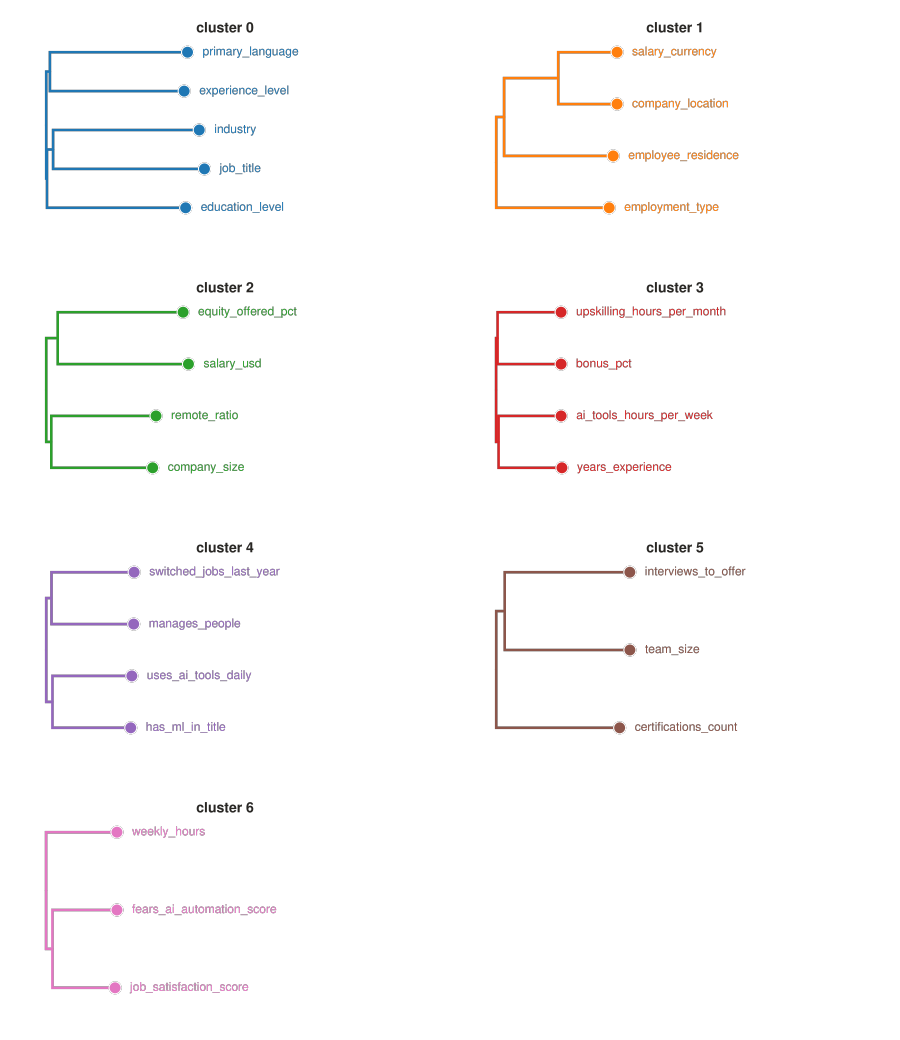

In [ ]:
import toyplot

# One panel per cluster: the tree pruned to that cluster's columns, in the cluster's color.
clusters_pdf_path = results_dir / "clusters_colored.pdf"
columns = 2
rows = -(-len(cluster_color) // columns)
cluster_canvas = toyplot.Canvas(width=900, height=260 * rows)

for position, (cluster, color) in enumerate(cluster_color.items()):
    members = membership.index[membership["cluster"] == cluster].tolist()
    subtree = tree.mod.prune(*members)
    panel = cluster_canvas.cartesian(
        grid=(rows, columns, position), label=f"cluster {cluster}", margin=45
    )
    subtree.draw(
        axes=panel,
        layout="r",
        tip_labels=[membership.at[subtree[i].name, "label"] for i in range(subtree.ntips)],
        tip_labels_colors=color,
        tip_labels_style={"font-size": "12px"},
        edge_colors=color,
        edge_widths=2.5,
        node_mask=False,
        node_sizes=[12 if subtree[i].is_leaf() else 0 for i in range(subtree.nnodes)],
        node_colors=color,
        node_style={"stroke": "white", "stroke-width": 1},
    )
    panel.x.show = False
    panel.y.show = False
    print(f"cluster {cluster}: {', '.join(membership.loc[members, 'label'])}")

toyplot.pdf.render(cluster_canvas, str(clusters_pdf_path))
print(f"PDF salvo em {clusters_pdf_path.resolve()}")
cluster_canvas